# Quality profiles: the examples of the paper

This notebook reproduces the main examples of

> G. Fasano, C. Piermarini, M. Roma. *Benchmarking Optimization Algorithms with Quality Profiles and Test Set Profiles.* Mathematical Programming Computation (accepted), [arXiv:2607.16798](https://arxiv.org/abs/2607.16798).

It uses the results published with the paper, which are stored in `examples/data`. Quality profiles compare solvers by the **quality of the solution** they return. For a set of test problems $P$, the profile of solver $s$ is

$$
Q_s(\tau) = \frac{1}{|P|}\,\mathrm{size}\Big\{p \in P : f_s^{(p)} - f_L^{(p)} \le \tau\,\big(f^{(p)}(x_0^{(p)}) - f_L^{(p)}\big)\Big\}, \qquad \tau \in [0, 1],
$$

where $f_s^{(p)}$ is the best value found by $s$ on problem $p$, $f^{(p)}(x_0^{(p)})$ is the value at the common starting point, and $f_L^{(p)}$ is the best value found by any solver. In practice one plots $[Q_s(\tau^{r_1})]^{r_2}$: `r1` zooms the abscissa and `r2` zooms the ordinate.

For every test problem the package only needs `f0[p]`, the value at the starting point, and `f_solvers[p, s]`, the best value found by each solver (`NaN` for a failure).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from quality_profiles import plot_quality_profiles, quality_profiles

plt.rcParams["figure.dpi"] = 110


def find_data_dir():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        candidate = folder / "examples" / "data"
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError("run this notebook from inside the quality-profiles repository")


DATA = find_data_dir()


def load(name):
    """Return (f0, f_solvers, solver_names) for one of the paper's experiments."""
    path = DATA / f"{name}.csv"
    names = path.read_text(encoding="utf-8").splitlines()[0].split(",")[1:]
    data = np.loadtxt(path, delimiter=",", skiprows=1)
    return data[:, 0], data[:, 1:], names


def shared_legend(fig, ax):
    """One legend for a multi-panel figure, outside the panels."""
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside right center", frameon=False, handlelength=3.2)


def show(qp, levels):
    """Print the profiles at a few precision levels."""
    width = max(len(n) for n in qp.solver_names) + 2
    print(f"{'precision':>10}" + "".join(f"{n:>{width}}" for n in qp.solver_names))
    for level, row in zip(levels, qp.evaluate(levels), strict=True):
        print(f"{level:>10.0e}" + "".join(f"{v:>{width}.2f}" for v in row))

## 1. A first example on random data (Section 4)

The paper starts its test set example with 100 random problems and three solvers. Their final values are drawn so that Solver-1 and Solver-2 behave almost alike, while Solver-3 is clearly more accurate:

$$
f(x_0) = -1 + 2\,\mathrm{rand}, \quad f_1 = -2 + 2\,\mathrm{rand}, \quad f_2 = -2.01 + 2\,\mathrm{rand}, \quad f_3 = -3 + 2\,\mathrm{rand}.
$$

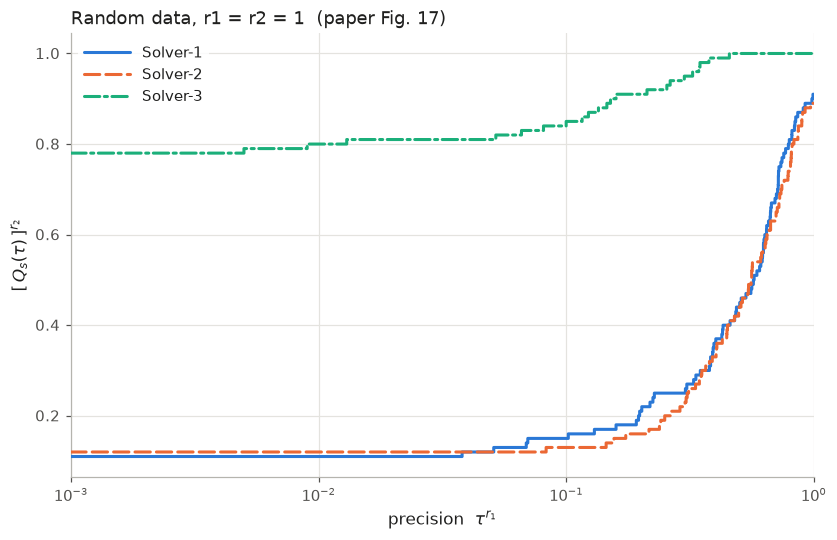

In [2]:
rng = np.random.default_rng(0)
n = 100
f0 = -1 + 2 * rng.random(n)
f_solvers = np.column_stack(
    [-2 + 2 * rng.random(n), -2.01 + 2 * rng.random(n), -3 + 2 * rng.random(n)]
)

qp = quality_profiles(f0, f_solvers)
plot_quality_profiles(qp, title="Random data, r1 = r2 = 1  (paper Fig. 17)")
plt.show()

How to read a quality profile:

* the value at precision $10^{-k}$ is the fraction of problems on which the solver reduced $f(x_0) - f_L$ by at least $k$ orders of magnitude;
* the value at $\tau = 1$ is the fraction of problems on which the solver did not fail and did not end above $f(x_0)$. Solver-1 and Solver-2 can end above $f(x_0)$ with this data, so they stay below 1;
* the value at $\tau = 0$ is the fraction of problems on which the solver found the best value among all solvers. It cannot be shown on a log axis, but `evaluate` gives it;
* the higher the curve, the better: here Solver-3 is uniformly preferable.

In [3]:
show(qp, [1.0, 1e-1, 1e-3, 0.0])

 precision  Solver-1  Solver-2  Solver-3
     1e+00      0.91      0.89      1.00
     1e-01      0.15      0.13      0.85
     1e-03      0.11      0.12      0.78
     0e+00      0.11      0.12      0.77


## 2. Zooming on 30 orders of magnitude (Figures 2 and 3)

Two solvers are compared on 166 problems whose final values span about 30 orders of magnitude. With the default `r1 = 1`, the grid only reaches precision $10^{-3}$. Increasing `r1` moves the samples towards 0, so the plot covers the high-accuracy range:

* `r1 = 10` reaches $10^{-40}$;
* `r1 = 4` reaches about $10^{-14}$.

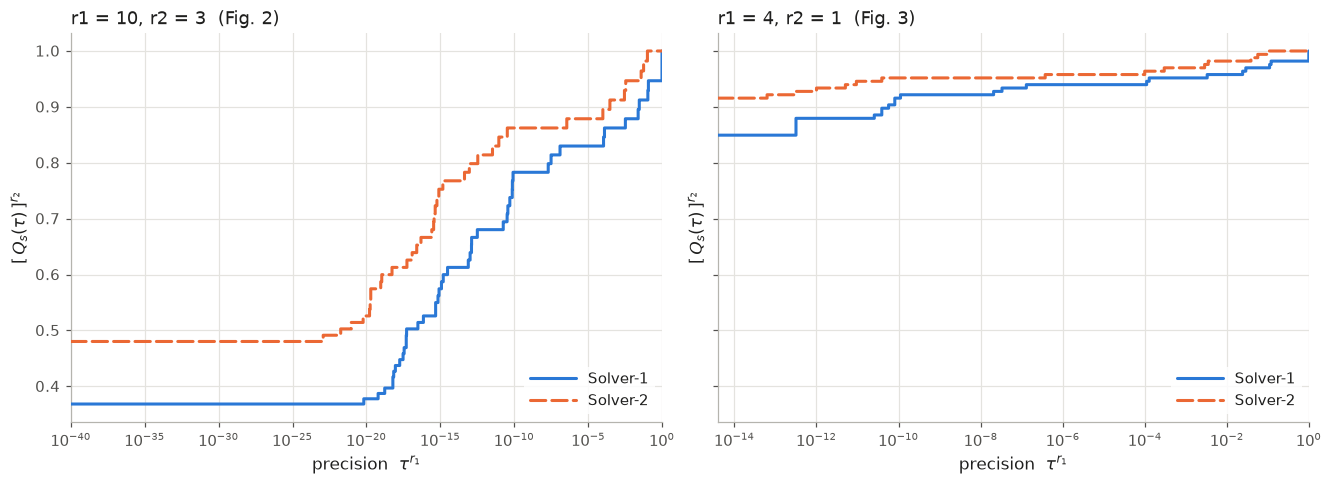

In [4]:
f0, f_solvers, names = load("two_solvers")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained", sharey=True)
for ax, (r1, r2, fig_id) in zip(axes, [(10, 3, 2), (4, 1, 3)], strict=True):
    qp = quality_profiles(f0, f_solvers, solver_names=names, r1=r1, r2=r2)
    plot_quality_profiles(
        qp, ax, title=f"r1 = {r1}, r2 = {r2}  (Fig. {fig_id})", legend_loc="lower right"
    )
plt.show()

Solver-2 is above Solver-1 everywhere, so it is uniformly preferable. Neither curve starts at 0: each solver finds the best value on a good share of the problems.

**A word of caution about `r2`.** The ranking of the solvers never depends on `r1` or `r2`, but the values on the ordinate do. With `r2 = 3` they are cubed, so the same precision level reads very differently in the two panels:

In [5]:
for r2 in (3, 1):
    qp = quality_profiles(f0, f_solvers, solver_names=names, r2=r2)
    print(f"r2 = {r2}:", dict(zip(names, qp.evaluate([1e-10])[0].round(3).tolist(), strict=True)))

r2 = 3: {'Solver-1': 0.783, 'Solver-2': 0.862}
r2 = 1: {'Solver-1': 0.922, 'Solver-2': 0.952}


With `r2 = 1` the values are plain fractions: Solver-1 reduces the initial gap by at least 10 orders of magnitude on 92% of the problems, Solver-2 on 95%. Use `r2 != 1` only to separate curves that are very close, and switch back to `r2 = 1` to read off percentages.

## 3. Smooth optimization: L-BFGS, CG+, TRON, CG_DESCENT (Figures 4, 5 and 8)

The paper compares four solvers on 166 large-scale unconstrained CUTEst problems. With `r1 = 1` the plot covers precisions from $10^{-3}$ to 1 (low accuracy). With `r1 = 5` it reaches about $10^{-18}$ (high accuracy).

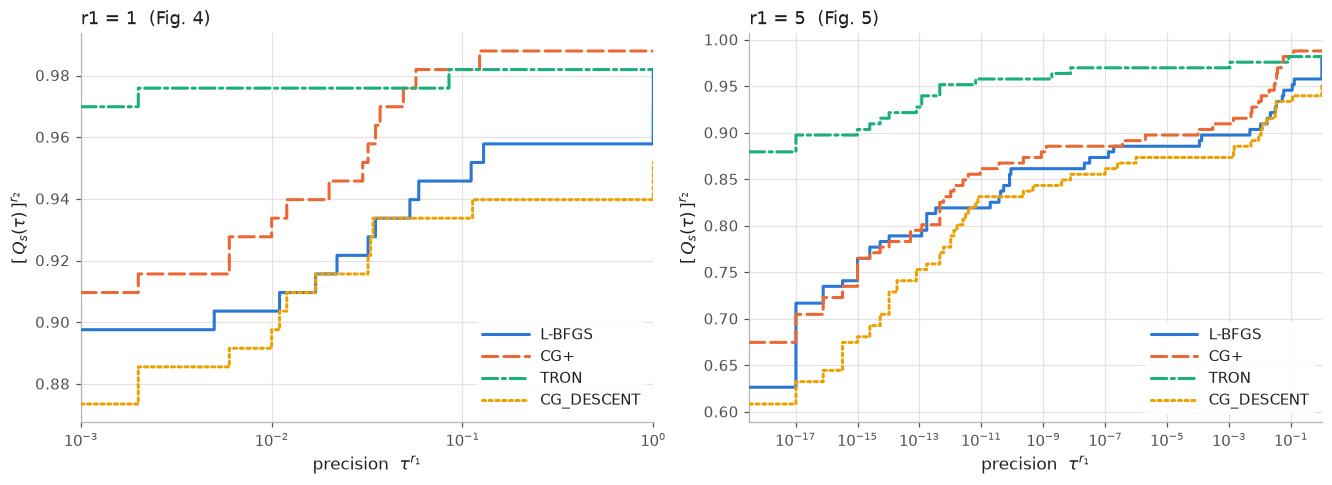

 precision      L-BFGS         CG+        TRON  CG_DESCENT
     1e+00        0.98        0.99        0.98        0.95
     1e-03        0.90        0.91        0.97        0.87
     1e-06        0.89        0.89        0.97        0.87
     1e-10        0.86        0.87        0.96        0.83
     0e+00        0.52        0.56        0.84        0.49


In [6]:
f0, f_solvers, names = load("cutest_smooth")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")
for ax, (r1, fig_id) in zip(axes, [(1, 4), (5, 5)], strict=True):
    qp = quality_profiles(f0, f_solvers, solver_names=names, r1=r1)
    plot_quality_profiles(qp, ax, title=f"r1 = {r1}  (Fig. {fig_id})", legend_loc="lower right")
plt.show()

show(quality_profiles(f0, f_solvers, solver_names=names), [1.0, 1e-3, 1e-6, 1e-10, 0.0])

* **TRON** finds the best value on 84% of the problems (precision 0) and stays on top over the whole high-accuracy range.
* **CG+** has the fewest failures: its value at precision 1 is the highest (0.988).
* With `r1 = 1` the four curves are close and hard to tell apart; `r1 = 5` makes the differences visible.

A linear abscissa, as in Fig. 8, squeezes the whole high-accuracy range into the left edge of the plot. The dashed guides mark 1, 2 and 3 orders of magnitude. This is why the log scale is recommended.

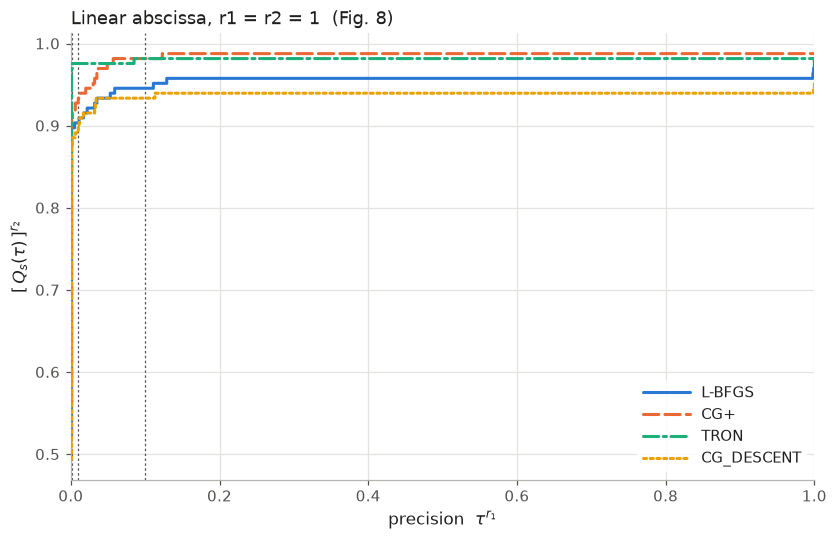

In [7]:
qp = quality_profiles(f0, f_solvers, solver_names=names)
plot_quality_profiles(
    qp, logscale=False, title="Linear abscissa, r1 = r2 = 1  (Fig. 8)", legend_loc="lower right"
)
plt.show()

## 4. Negative curvature in truncated Newton methods (Figures 9 to 11)

The four truncated Newton variants differ only in how they build the negative curvature direction. With `r1 = r2 = 1` three of the curves overlap. Expanding the abscissa (`r1 = 5`), and then also the ordinate (`r2 = 3`), separates them.

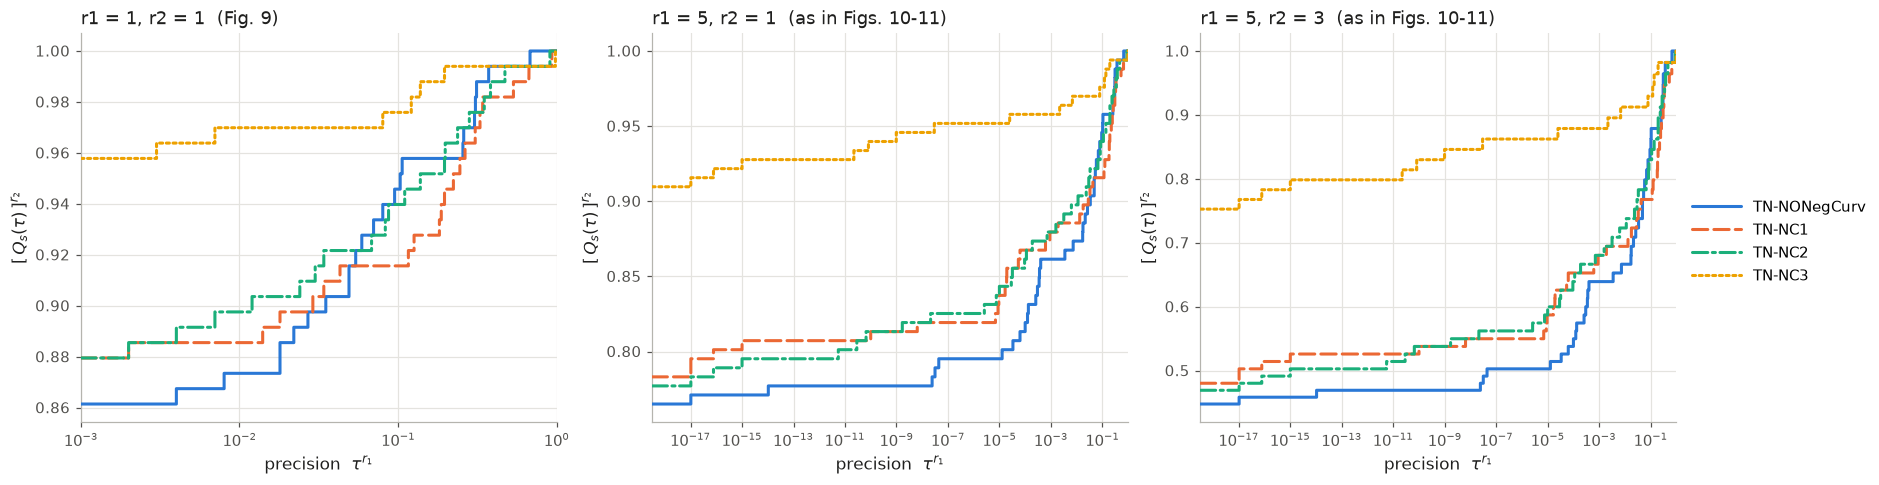

In [8]:
f0, f_solvers, names = load("negative_curvature")

settings = [(1, 1, "Fig. 9"), (5, 1, "as in Figs. 10-11"), (5, 3, "as in Figs. 10-11")]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), layout="constrained")
for ax, (r1, r2, label) in zip(axes, settings, strict=True):
    qp = quality_profiles(f0, f_solvers, solver_names=names, r1=r1, r2=r2)
    plot_quality_profiles(qp, ax, title=f"r1 = {r1}, r2 = {r2}  ({label})", legend=False)
shared_legend(fig, ax)
plt.show()

**TN-NC3**, which uses only the first negative eigenvalue, is the most effective variant: it is on top everywhere except very close to precision 1, where TN-NONegCurv catches up. The zoomed panels also show that the variants using negative curvature (NC1, NC2, NC3) reach high accuracy more often than TN-NONegCurv.

## 5. Derivative-free optimization: the effect of the budget (Figures 12 to 15)

Seven derivative-free solvers are run on 145 CUTEst problems with budgets of 250·n, 500·n, 750·n and 1000·n function evaluations, giving one quality profile per budget. ALG1 to ALG8 are COORD, COMPASS, H&J, SH&H, NM and SMD from the Direct Search suite. The panels use `r1 = 5` to show the high-accuracy range.

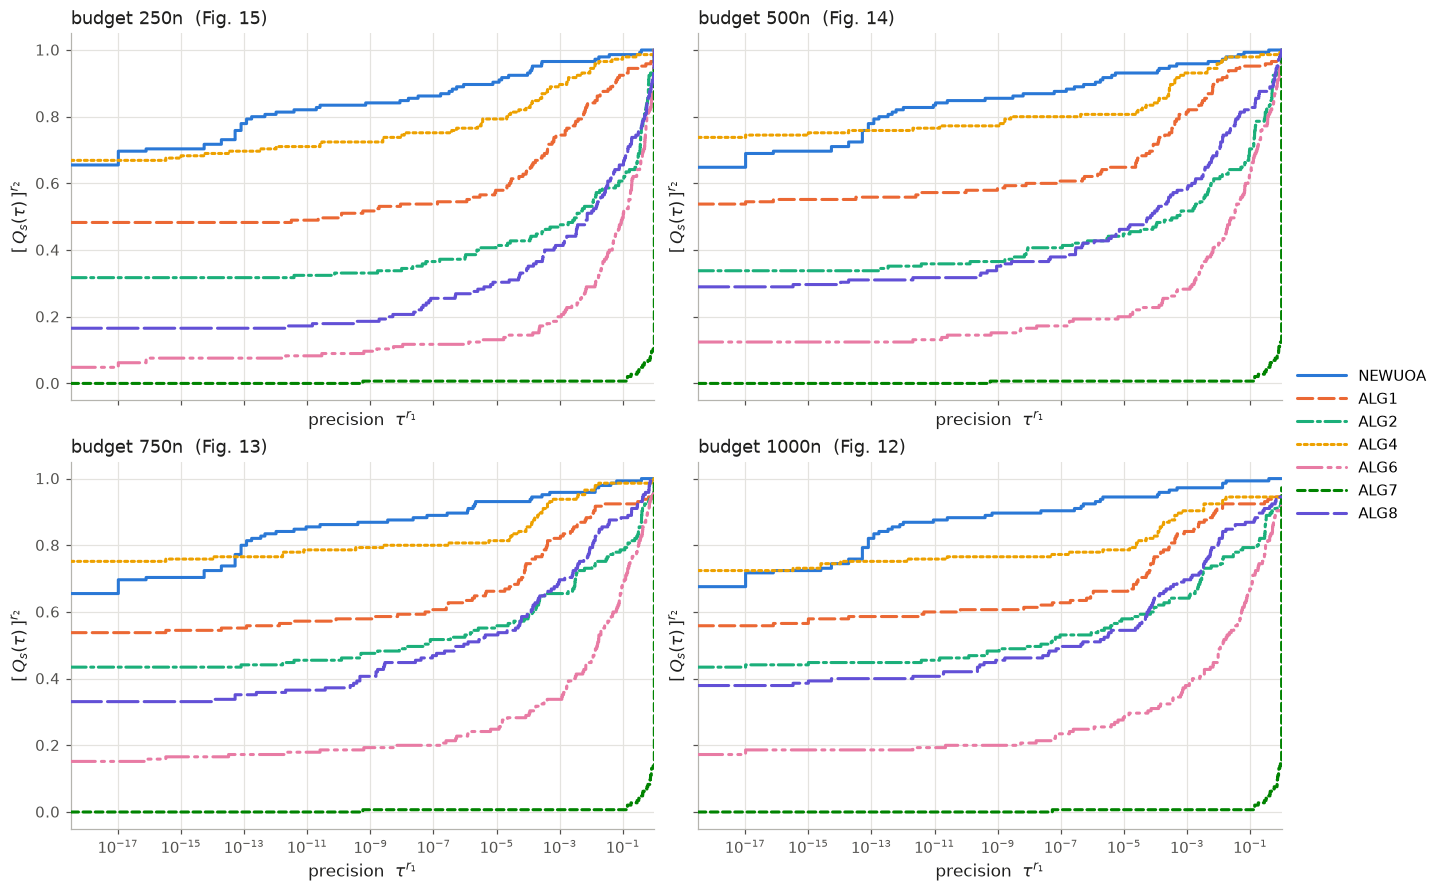

In [9]:
budgets = ["250n", "500n", "750n", "1000n"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained", sharex=True, sharey=True)
for ax, budget, fig_id in zip(axes.flat, budgets, [15, 14, 13, 12], strict=True):
    f0, f_solvers, names = load(f"dfo_budget_{budget}")
    qp = quality_profiles(f0, f_solvers, solver_names=names, r1=5)
    plot_quality_profiles(qp, ax, title=f"budget {budget}  (Fig. {fig_id})", legend=False)
shared_legend(fig, ax)
plt.show()

* **NEWUOA**, the only model-based method, is the most accurate at every budget and keeps improving at a fairly constant rate.
* The pattern-search methods make quick initial progress but struggle at high precision. More budget mostly lifts their curves at high accuracy: at precision $10^{-12}$, ALG8 goes from 17% of the problems (250·n) to 40% (1000·n).

Values of `r1` smaller than 1 zoom in near precision 1 instead, where the differences between the pattern-search methods show up:

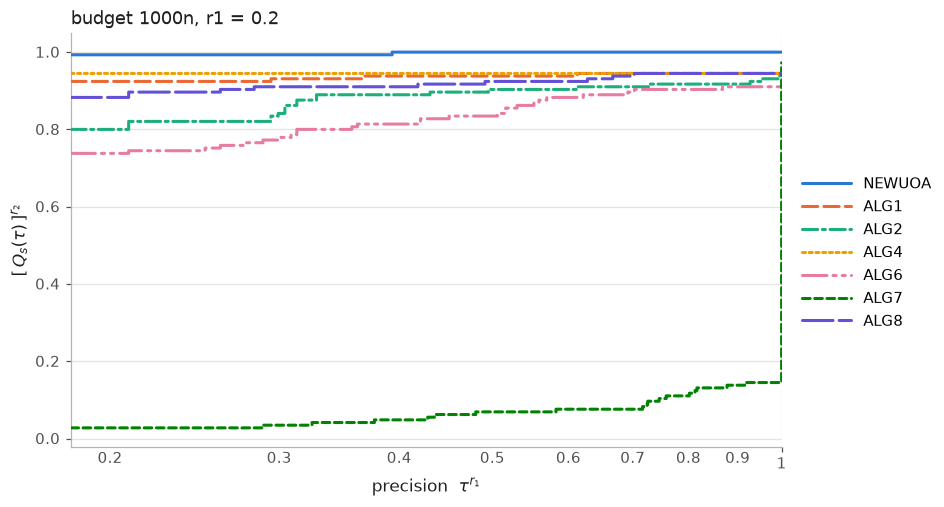

In [10]:
f0, f_solvers, names = load("dfo_budget_1000n")
qp = quality_profiles(f0, f_solvers, solver_names=names, r1=0.2)

fig, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
plot_quality_profiles(qp, ax, title="budget 1000n, r1 = 0.2", legend=False)
shared_legend(fig, ax)
plt.show()

## 6. One number per solver

The area under a profile is a single score per solver (Observation 2.9): the larger, the better. It is computed with respect to $\tau$, so `r1 > 1` gives more weight to high accuracy. On the smooth test set the leader changes: CG+ wins at low accuracy and TRON at high accuracy.

In [11]:
f0, f_solvers, names = load("cutest_smooth")
for r1 in (1, 5):
    ranking = quality_profiles(f0, f_solvers, solver_names=names, r1=r1).ranking()
    print(f"r1 = {r1}:  " + ",  ".join(f"{name} {area:.3f}" for name, area in ranking))

r1 = 1:  CG+ 0.985,  TRON 0.981,  L-BFGS 0.955,  CG_DESCENT 0.938
r1 = 5:  TRON 0.976,  CG+ 0.948,  L-BFGS 0.924,  CG_DESCENT 0.910


A single number cannot show where curves cross, so always look at the profiles too.

## 7. Strong profiles

`strong=True` measures each solver against the **worst** value found by the solvers instead of $f(x_0)$. This helps when the solvers end up close to each other, as the truncated Newton variants do. Every profile then reaches its maximum at $\tau = 1$, because the worst solver is exactly at the reference.

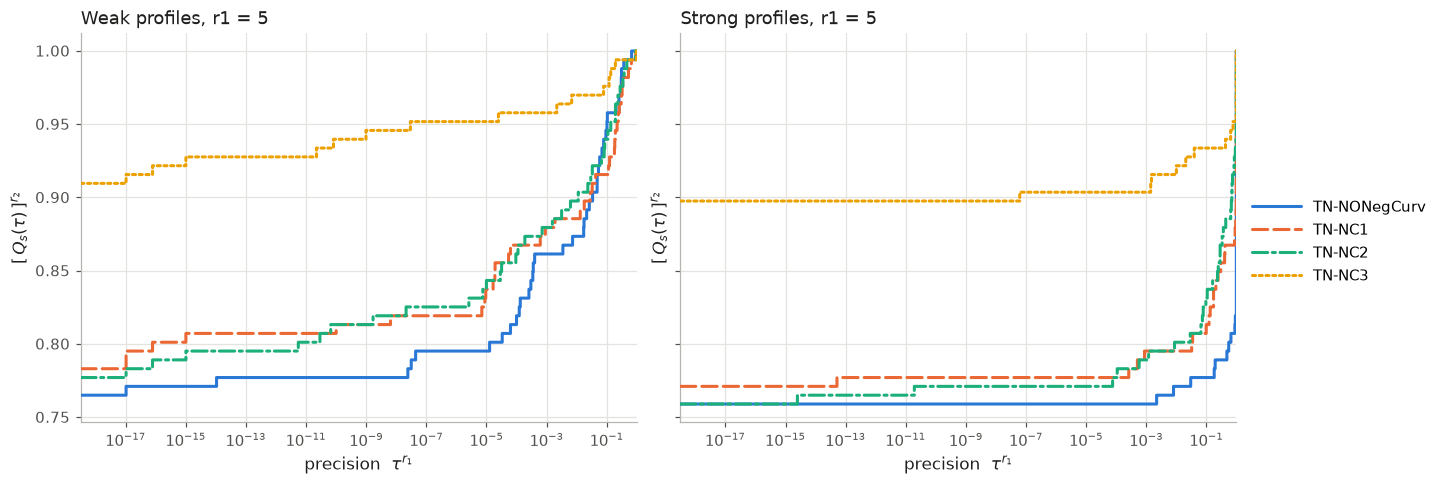

In [12]:
f0, f_solvers, names = load("negative_curvature")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), layout="constrained", sharey=True)
for ax, strong in zip(axes, (False, True), strict=True):
    qp = quality_profiles(f0, f_solvers, solver_names=names, r1=5, strong=strong)
    plot_quality_profiles(
        qp, ax, title=f"{'Strong' if strong else 'Weak'} profiles, r1 = 5", legend=False
    )
shared_legend(fig, ax)
plt.show()

## 8. Using your own results

Collect, for every test problem, the value at the starting point and the best value found by each solver, then call `quality_profiles`:

```python
qp = quality_profiles(f0, f_solvers, solver_names=["my solver", "baseline"], r1=5)
plot_quality_profiles(qp)
```

If the results are stored like the `TT` matrix of the MATLAB code (first column $f(x_0)$, then one column per solver), `split_matrix` splits them. `plot_quality_profiles(qp, colors="paper")` uses the paper's red-to-blue colors.